<a href="https://colab.research.google.com/github/A-KOStov/Evlash-Valeria-2253/blob/main/task_5_%E2%84%961.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [37]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

In [38]:
t = sp.Symbol('t')
x = sp.Function('x')

In [39]:
m_val = 1
x0_val = 0.1
v0_val = 0
k_vals = [1, 4, 9, 16, 25]
t_span = np.linspace(0, 10, 1000)

In [40]:
m_sym, k_sym = sp.symbols('m k', positive=True)
eq1 = sp.Eq(m_sym * sp.diff(x(t), t, 2) + k_sym * x(t), 0)
gen_sol = sp.dsolve(eq1)
print("Общее решение:")
sp.pprint(gen_sol)

Общее решение:
             ⎛√k⋅t⎞         ⎛√k⋅t⎞
x(t) = C₁⋅sin⎜────⎟ + C₂⋅cos⎜────⎟
             ⎝ √m ⎠         ⎝ √m ⎠


In [41]:
x0_sym, v0_sym = sp.symbols('x0 v0')
solutions = []

In [42]:
for k_val in k_vals:
    eq_num = sp.Eq(m_val * sp.diff(x(t), t, 2) + k_val * x(t), 0)
    sol = sp.dsolve(eq_num, ics={x(0): x0_val, sp.diff(x(t), t).subs(t, 0): v0_val})
    solutions.append((k_val, sol.rhs))

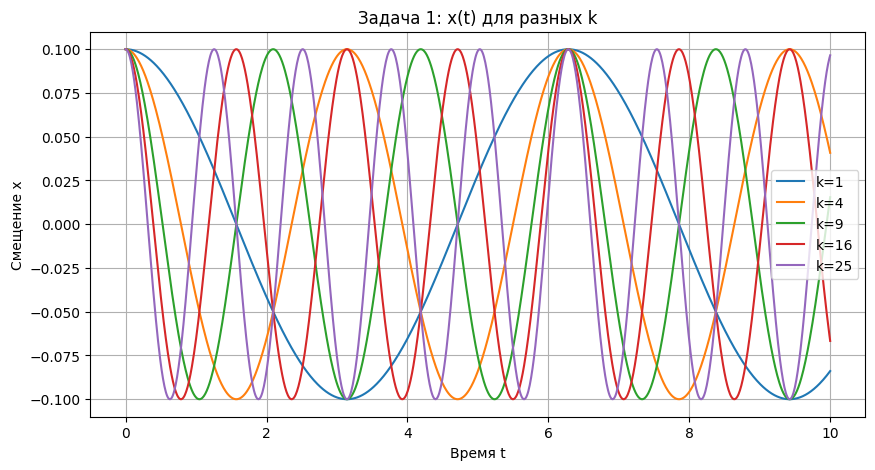

In [45]:
plt.figure(figsize=(10, 5))
for k_val, sol_rhs in solutions:
    f_x = sp.lambdify(t, sol_rhs, 'numpy')
    plt.plot(t_span, f_x(t_span), label=f'k={k_val}')
    plt.title('Задача 1: x(t) для разных k')
plt.xlabel('Время t')
plt.ylabel('Смещение x')
plt.legend()
plt.grid(True)
plt.show()

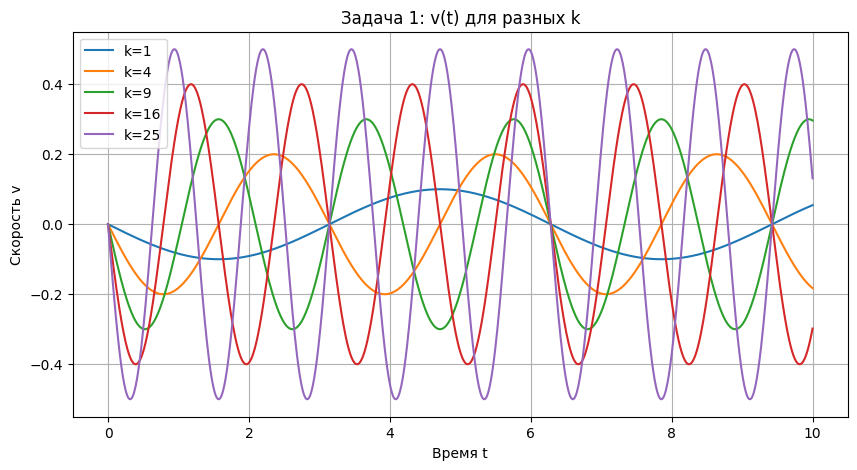

In [46]:
plt.figure(figsize=(10, 5))
for k_val, sol_rhs in solutions:
    v_sym = sp.diff(sol_rhs, t)
    f_v = sp.lambdify(t, v_sym, 'numpy')
    plt.plot(t_span, f_v(t_span), label=f'k={k_val}')
    plt.title('Задача 1: v(t) для разных k')
plt.xlabel('Время t')
plt.ylabel('Скорость v')
plt.legend()
plt.grid(True)
plt.show()

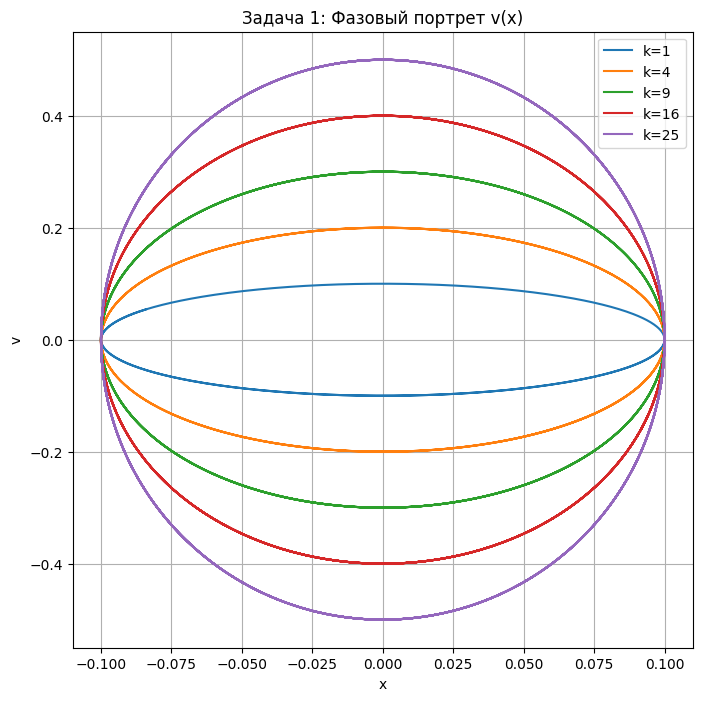

In [47]:
plt.figure(figsize=(8, 8))
for k_val, sol_rhs in solutions:
    v_sym = sp.diff(sol_rhs, t)
    x_arr = sp.lambdify(t, sol_rhs, 'numpy')(t_span)
    v_arr = sp.lambdify(t, v_sym, 'numpy')(t_span)
    plt.plot(x_arr, v_arr, label=f'k={k_val}')
    plt.title('Задача 1: Фазовый портрет v(x)')
plt.xlabel('x')
plt.ylabel('v')
plt.legend()
plt.grid(True)
plt.show()